# Шаг 7. Кошка или собака? Проверяем сеть на своих фотографиях

Самая честная проверка — на фото, которых **нет ни в каком наборе данных**: ваш кот, собака соседа, картинка из интернета.

Сеть училась на картинках 32 × 32, поэтому любое фото нужно подготовить так же:
1. **обрезать до квадрата** по центру (иначе при уменьшении животное сплющится);
2. **уменьшить до 32 × 32**;
3. превратить в тензор `(1, 3, 32, 32)` с числами от 0 до 1 и порядком каналов **RGB**.

> Положите свои фото (`.jpg`, `.jpeg`, `.png`) в папку `my_photos` рядом с этим ноутбуком.
> Если папки нет, сеть проверяется на 8 случайных картинках из проверочного набора.
> Нужна обученная сеть `cnn_aug.pt` (шаг 5).

**Структура примера (алгоритм):**
1. Загружаем обученную сеть.
2. Ищем фото в папке `my_photos`.
3. Каждое фото готовим «как в CIFAR»: квадрат → 32 × 32 → тензор.
4. Получаем от сети вероятности «кошка» и «собака».
5. Рисуем исходное фото, то, что видит сеть, и ответ.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Сеть и список фотографий

- `PIL.Image` (библиотека Pillow) открывает jpg и png; `.convert("RGB")` приводит любую картинку к трём каналам
  (у png бывает четвёртый — прозрачность, а у серых фото — всего один).
- `Path(...).glob("*")` перебирает файлы в папке; оставляем только файлы с подходящим расширением.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.transforms.v2 import functional as TF

from common import CLASSES, CLASSES_RU, CatsDogs, SimpleCNN, load_model, show

model = load_model(SimpleCNN(dropout=0.3), "cnn_aug")

PHOTOS = Path("my_photos")
files = sorted(p for p in PHOTOS.glob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
print("Своих фото:", len(files))

Своих фото: 0


## 2. Подготовка фото «как в CIFAR»

Функция `prepare`:
1. `TF.pil_to_tensor(photo)` — картинка Pillow в тензор `(3, высота, ширина)` с байтами 0…255;
2. `TF.center_crop(x, side)` — вырезает из центра квадрат со стороной `side` = меньшая из сторон фото;
3. `TF.resize(x, [32, 32], antialias=True)` — уменьшает до 32 × 32. `antialias=True` усредняет пиксели, а не выкидывает их —
   иначе на сильно уменьшенной картинке появится «шум»;
4. `/ 255` — байты в дроби 0…1, как при обучении.

Если своих фото нет, берём 8 случайных картинок проверочного набора — они уже 32 × 32, их готовить не нужно.

In [2]:
def prepare(photo):
    """Фото любого размера → тензор (3, 32, 32), числа 0..1, как картинки CIFAR."""
    x = TF.pil_to_tensor(photo)                      # (3, H, W), байты 0..255
    x = TF.center_crop(x, min(x.shape[1:]))          # квадрат из центра
    x = TF.resize(x, [32, 32], antialias=True)       # 32×32
    return x.float() / 255


if files:
    originals = [Image.open(p).convert("RGB") for p in files]
    names = [p.name for p in files]
    small = torch.stack([prepare(photo) for photo in originals])
else:
    print("Папки my_photos нет или она пустая — берём случайные картинки из проверочного набора")
    test = CatsDogs(train=False)
    picks = torch.randint(len(test), (8,)).tolist()
    small = test.images[picks]
    originals = [img.permute(1, 2, 0) for img in small]
    names = [f"test #{i}: {CLASSES[test.labels[i]]}" for i in picks]
print("Пачка для сети:", tuple(small.shape))

Папки my_photos нет или она пустая — берём случайные картинки из проверочного набора
Пачка для сети: (8, 3, 32, 32)


## 3. Ответ сети

Вся пачка фото обрабатывается за один вызов `model(small)`. `softmax` превращает две оценки в вероятности, в сумме дающие 1.

In [3]:
with torch.no_grad():
    probs = torch.softmax(model(small), dim=1)

for name, p in zip(names, probs):
    best = p.argmax().item()
    print(f"{name:<28} → {CLASSES_RU[best]:<7} ({p[best].item():.0%})")

test #1699: dog              → собака  (93%)
test #981: dog               → собака  (99%)
test #1234: cat              → кошка   (85%)
test #714: cat               → кошка   (99%)
test #464: dog               → собака  (72%)
test #1207: cat              → кошка   (98%)
test #1612: dog              → собака  (58%)
test #1977: dog              → собака  (98%)


## 4. Картинка с ответами

Верхний ряд — исходное фото, нижний — то, что на самом деле видит сеть (32 × 32, увеличено без сглаживания).
Многие детали, по которым **человек** узнаёт кошку, при уменьшении до 32 × 32 просто исчезают.
Это главное ограничение нашей маленькой сети: чтобы работать с настоящими фото, нужны картинки побольше
и сети поглубже — например, готовые сети, обученные на миллионах фото (**перенос обучения**, *transfer learning*).

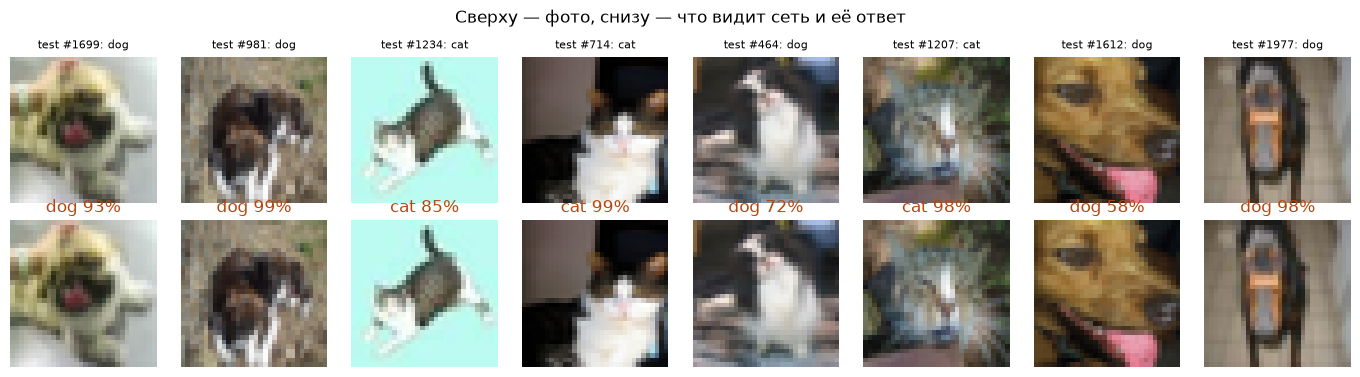

In [4]:
n = len(names)
fig, axes = plt.subplots(2, n, figsize=(max(1.6 * n + 1, 6), 3.8), squeeze=False)
for col, (original, tiny, p, name) in enumerate(zip(originals, small, probs, names)):
    best = p.argmax().item()
    axes[0, col].imshow(original)
    axes[0, col].set_title(name, fontsize=8)
    axes[1, col].imshow(tiny.permute(1, 2, 0), interpolation="nearest")
    axes[1, col].set_title(f"{CLASSES[best]} {p[best].item():.0%}", color="#B8460A")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Сверху — фото, снизу — что видит сеть и её ответ")
plt.tight_layout()
plt.savefig("my_photos_result.png", dpi=100)
show()

## Попробуйте сами

1. Сфотографируйте кошку или собаку крупным планом и издалека. Когда сеть ошибается чаще?
2. Покажите сети фото человека, машины, тигра или лисы. Что она ответит? Может ли она сказать «ни то, ни другое»?
3. Отразите своё фото зеркально (`TF.horizontal_flip`) и сравните ответы. Помогает ли усреднение двух ответов?
4. Подумайте: как сделать сеть, которая умеет отвечать «здесь нет ни кошки, ни собаки»?